# 1. Environment Setup & Data Loading

In [1]:
import numpy as np 
import pandas as pd
import os
import kagglehub
# On Kaggle this returns the mounted /kaggle/input path; locally it downloads to the kagglehub cache (needs ~/.kaggle/access_token)
path = kagglehub.competition_download('playground-series-s6e3')
print("Path to competition files:", path)
print("--------------------------------------------------------------------------------")
for dirname, _, filenames in os.walk(path): # read and listing out all the file under the competition path
    for filename in filenames:
        print(os.path.join(dirname, filename))
print("--------------------------------------------------------------------------------")
print("Load and assigning dataset.....")

def load_csv(path, name="dataset"): # Functionfor try and catch error for loading csv in the notebook
    try:
        df = pd.read_csv(path)
        print(f"Success - {name} loaded successfully: {df.shape}")
        return df

    except FileNotFoundError:
        print(f"Failed - {name} not found: {path}")
        return None

    except pd.errors.EmptyDataError:
        print(f"Failed - {name} is empty: {path}")
        return None

    except pd.errors.ParserError:
        print(f"Failed - Could not parse {name}: {path}")
        return None

    except Exception as e:
        print(f"Failed - Error loading {name}: {e}")
        return None

train_raw = load_csv( # loading training dataset
    os.path.join(path, "train.csv"),
    "train_raw"
)

test_raw = load_csv( # loading testing dataset
    os.path.join(path, "test.csv"),
    "test_raw"
)

C:\Users\chano\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to competition files: C:\Users\chano\.cache\kagglehub\competitions\playground-series-s6e3
--------------------------------------------------------------------------------
C:\Users\chano\.cache\kagglehub\competitions\playground-series-s6e3\sample_submission.csv
C:\Users\chano\.cache\kagglehub\competitions\playground-series-s6e3\test.csv
C:\Users\chano\.cache\kagglehub\competitions\playground-series-s6e3\train.csv
--------------------------------------------------------------------------------
Load and assigning dataset.....


Success - train_raw loaded successfully: (594194, 21)


Success - test_raw loaded successfully: (254655, 20)


# 2. Explotanary Data ( EDA )

## 2.1 Examine the dataset

In [2]:
print(f"============================= Train Set =============================")
train_raw.info()
print(f"=====================================================================")
train_raw.head()

============================= Train Set =============================


<class 'pandas.DataFrame'>
RangeIndex: 594194 entries, 0 to 594193
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                594194 non-null  int64  
 1   gender            594194 non-null  str    
 2   SeniorCitizen     594194 non-null  int64  
 3   Partner           594194 non-null  str    
 4   Dependents        594194 non-null  str    
 5   tenure            594194 non-null  int64  
 6   PhoneService      594194 non-null  str    
 7   MultipleLines     594194 non-null  str    
 8   InternetService   594194 non-null  str    
 9   OnlineSecurity    594194 non-null  str    
 10  OnlineBackup      594194 non-null  str    
 11  DeviceProtection  594194 non-null  str    
 12  TechSupport       594194 non-null  str    
 13  StreamingTV       594194 non-null  str    
 14  StreamingMovies   594194 non-null  str    
 15  Contract          594194 non-null  str    
 16  PaperlessBilling  594194 non-nu

,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Male,0,Yes,Yes,29,Yes,No,DSL,Yes,...,Yes,Yes,No,No,One year,Yes,Mailed check,60.10,1653.85,No
1,1,Male,0,Yes,Yes,58,Yes,No,DSL,Yes,...,No,Yes,Yes,No,Two year,No,Credit card (automatic),69.50,3778.20,No
2,2,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.40,5841.35,No
3,3,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.70,70.70,Yes
4,4,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.45,70.45,Yes


## 2.2 EDA - test_set

In [3]:
test_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 254655 entries, 0 to 254654
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                254655 non-null  int64  
 1   gender            254655 non-null  str    
 2   SeniorCitizen     254655 non-null  int64  
 3   Partner           254655 non-null  str    
 4   Dependents        254655 non-null  str    
 5   tenure            254655 non-null  int64  
 6   PhoneService      254655 non-null  str    
 7   MultipleLines     254655 non-null  str    
 8   InternetService   254655 non-null  str    
 9   OnlineSecurity    254655 non-null  str    
 10  OnlineBackup      254655 non-null  str    
 11  DeviceProtection  254655 non-null  str    
 12  TechSupport       254655 non-null  str    
 13  StreamingTV       254655 non-null  str    
 14  StreamingMovies   254655 non-null  str    
 15  Contract          254655 non-null  str    
 16  PaperlessBilling  254655 non-nu

In [4]:
test_raw.head()

,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,594194,Female,0,Yes,No,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,115.55,8061.50
1,594195,Female,0,Yes,No,71,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.80,1336.50
2,594196,Male,0,No,No,12,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),55.55,633.55
3,594197,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic),84.10,6457.15
4,594198,Female,0,No,No,15,Yes,No,Fiber optic,Yes,No,No,No,Yes,Yes,Month-to-month,No,Electronic check,90.35,1233.65


## 2.4 Identifying target columns 

In [5]:
print("Train columns:")
print(train_raw.columns.tolist())

print("\nTest columns:")
print(test_raw.columns.tolist())

target_candidates = list(set(train_raw.columns) - set(test_raw.columns))

print("\nPossible target column(s):", target_candidates)

Train columns:
['id', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Test columns:
['id', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Possible target column(s): ['Churn']


## 2.5 Distribution of numeric columns

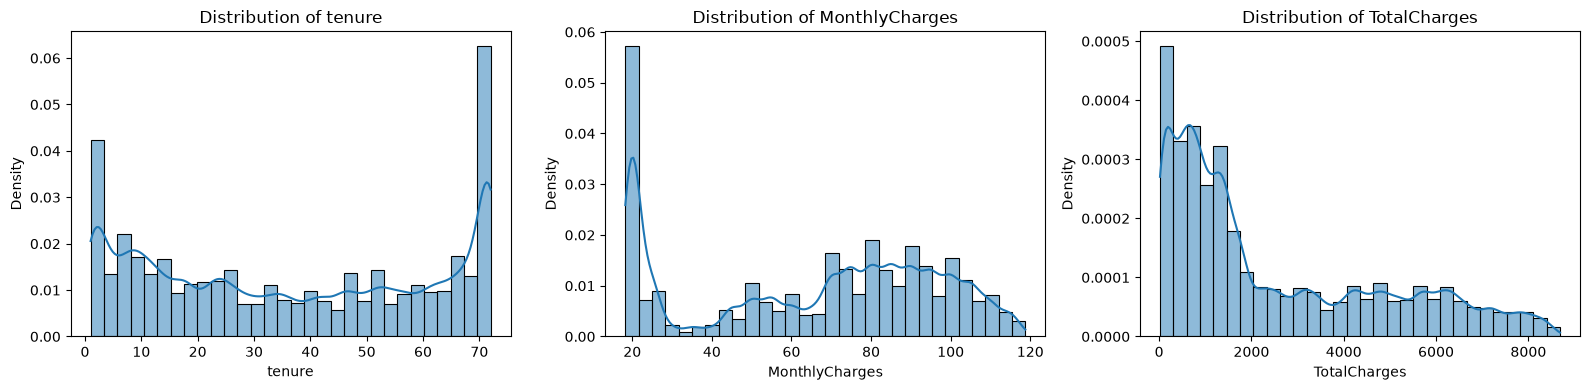

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Select numeric columns and exclude ID
numeric_cols = train_raw.select_dtypes(include="number").columns.drop(
    ["id", "SeniorCitizen"], errors="ignore"
)

# Plot settings
n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

# Make axes iterable even if there is only one subplot
axes = axes.flatten()

# Plot histogram + KDE for each numeric feature
for i, col in enumerate(numeric_cols):
    data = train_raw[col].dropna()

    sns.histplot(
        data,
        bins=30,
        kde=True,
        ax=axes[i],
        stat="density",
        edgecolor="black"
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Density")

# Hide unused subplots
for i in range(len(numeric_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

## 2.6 Distribution of categorical columns

C:\Users\chano\AppData\Local\Temp\ipykernel_24784\57014909.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_raw.select_dtypes(


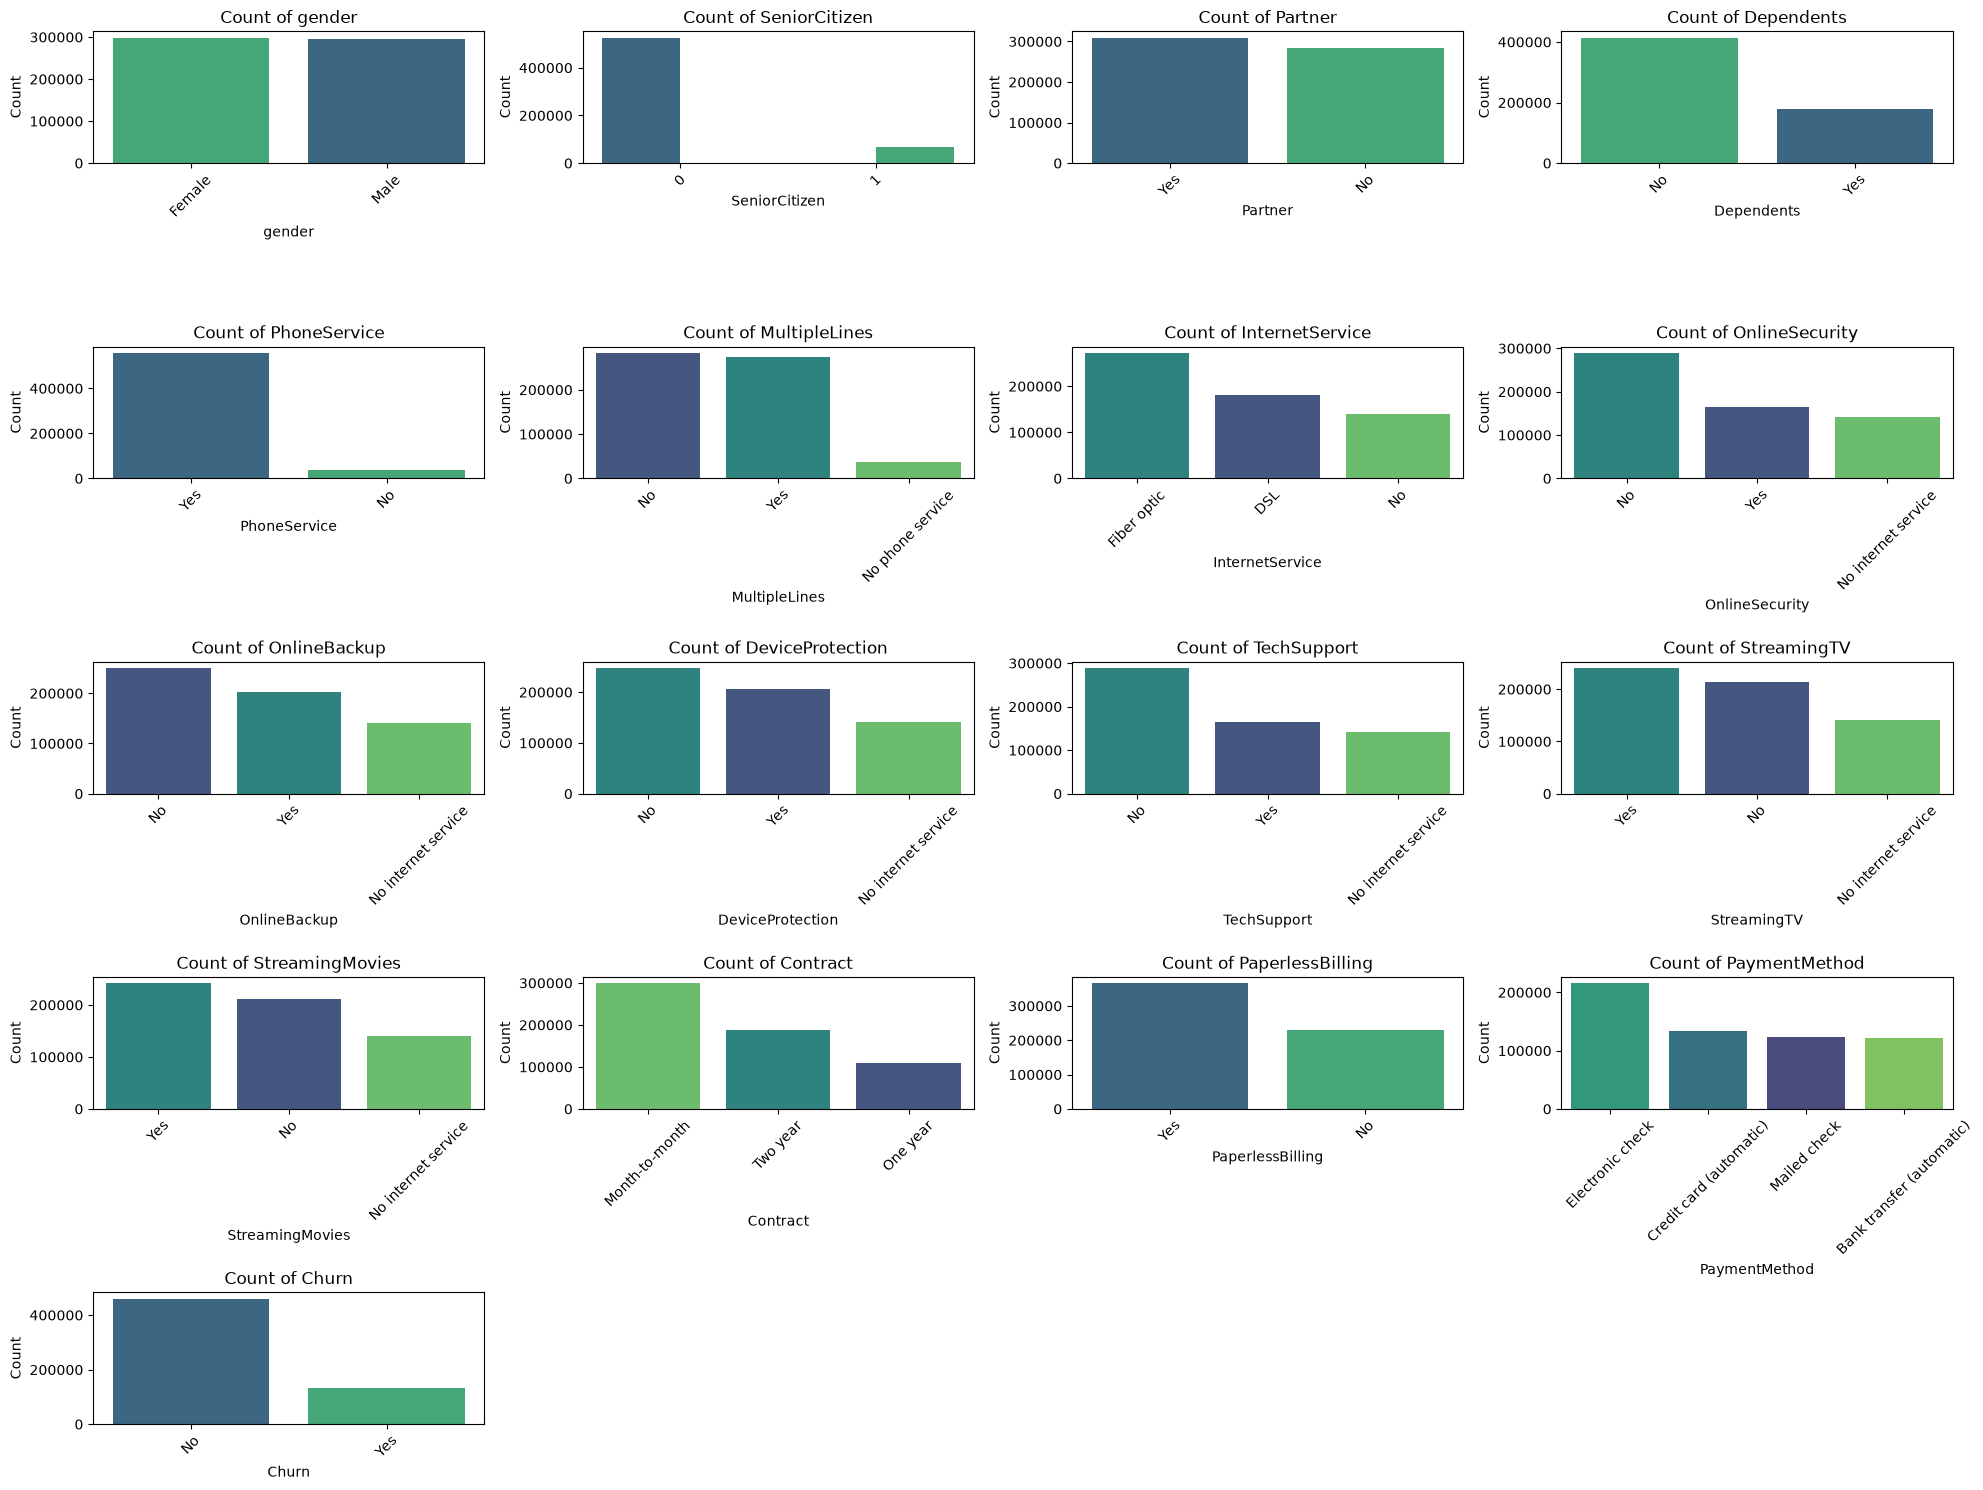

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

train_raw["SeniorCitizen"] = train_raw["SeniorCitizen"].astype("category") # assign seniorcitizen column as category type instead of numeric
test_raw["SeniorCitizen"] = test_raw["SeniorCitizen"].astype("category")

categorical_cols = train_raw.select_dtypes(
    include=["object", "category", "bool"]
).columns.drop("id", errors="ignore")\



plt.figure(figsize=(20, 15))

for i, col in enumerate(categorical_cols):
    plt.subplot(5, 4, i + 1)

    top_categories = train_raw[col].value_counts().head(10).index

    plot_data = train_raw[
        train_raw[col].isin(top_categories)
    ]

    sns.countplot(
        x=plot_data[col],
        hue=plot_data[col],
        order=top_categories,
        palette="viridis",
        legend=False
    )

    plt.title(f"Count of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# 3. Data processing

C:\Users\chano\AppData\Local\Temp\ipykernel_24784\3202551432.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = corr_data.select_dtypes(


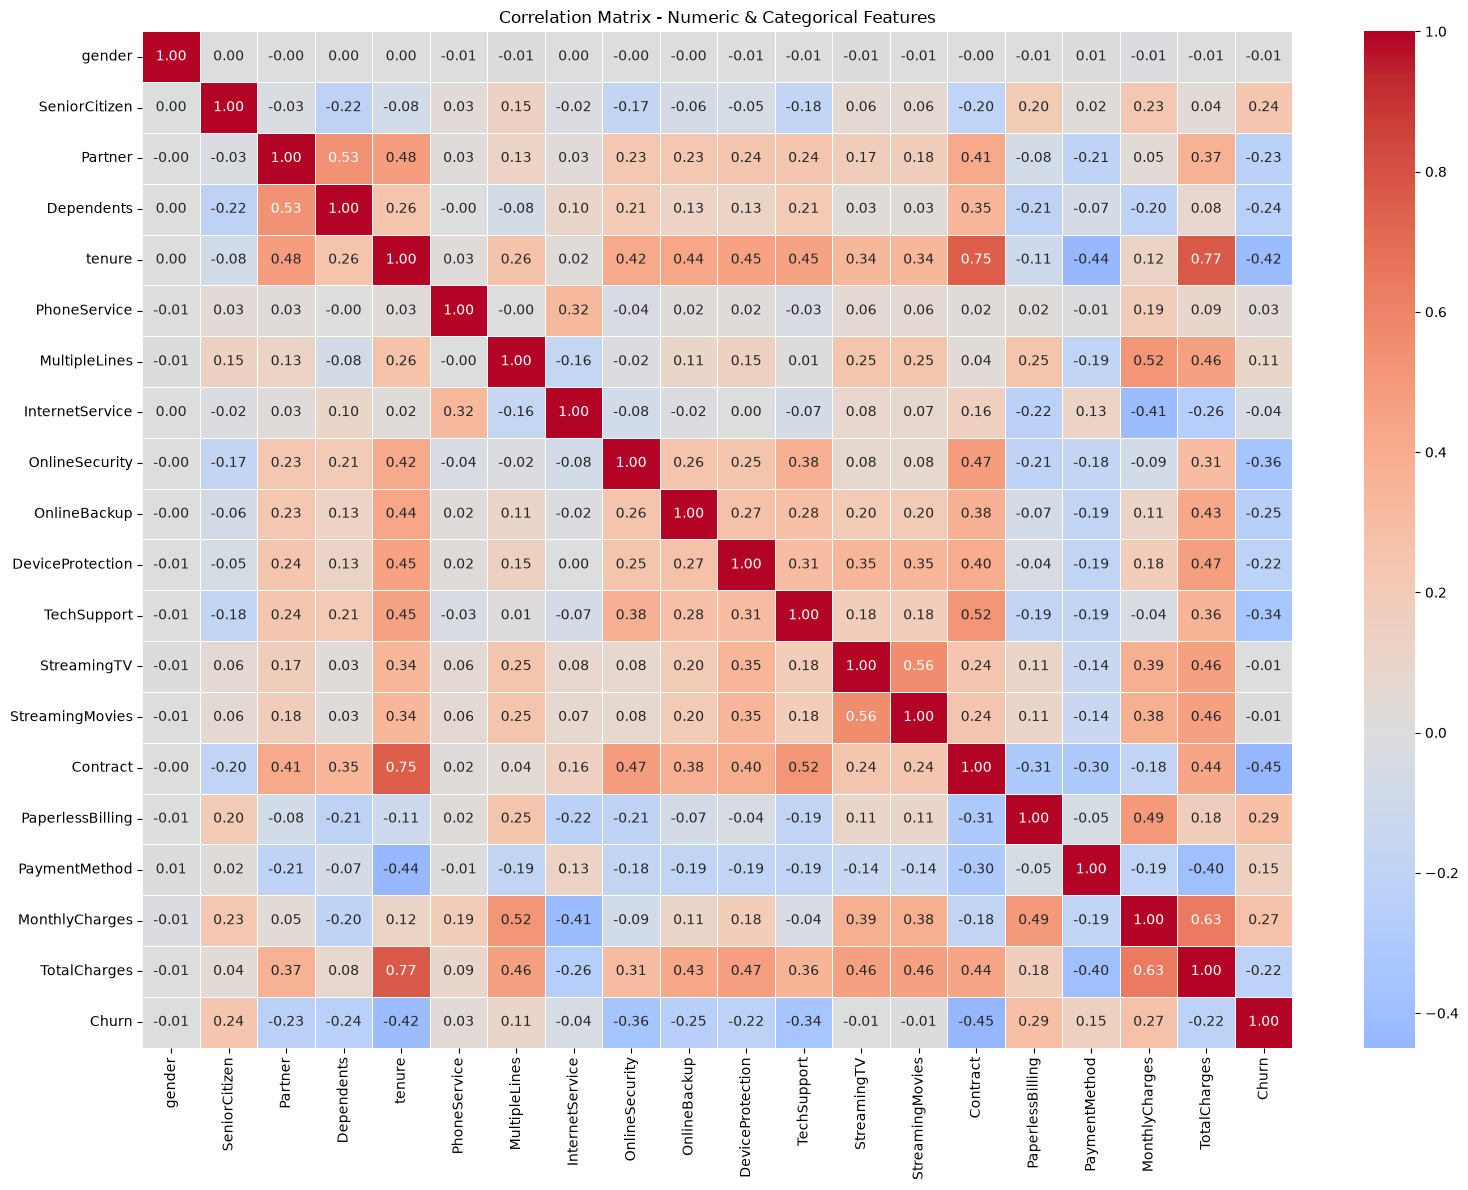

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make a copy so we don't modify train_raw
corr_data = train_raw.copy()

# Drop ID
corr_data = corr_data.drop(columns=["id"], errors="ignore")

# Convert categorical columns to numeric
categorical_cols = corr_data.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in categorical_cols:
    corr_data[col] = corr_data[col].astype("category").cat.codes

# Calculate correlation matrix
corr_matrix = corr_data.corr()

# Plot
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix - Numeric & Categorical Features")
plt.tight_layout()
plt.show()

# 4. Baseline model

In [9]:
# ============================================================
# 1. TRAIN / VALIDATION SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Separate features and target
X = train_raw.drop(columns=["Churn", "id"], errors="ignore")
y = train_raw["Churn"]

# Split BEFORE preprocessing/model training
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("=" * 70)
print("TRAIN / VALIDATION SPLIT")
print("=" * 70)
print(f"Full dataset     : {X.shape}")
print(f"Training set     : {X_train.shape}")
print(f"Validation set  : {X_valid.shape}")
print(f"Training target : {y_train.shape}")
print(f"Validation target: {y_valid.shape}")
print("=" * 70)


# ============================================================
# 2. BASIC PREPROCESSING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify columns from TRAINING SET only
numeric_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# ============================================================
# 3. BASELINE MODEL
# ============================================================

from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# ============================================================
# 4. TRAIN BASELINE MODEL
# ============================================================

print("\nTRAINING BASELINE MODEL........")
baseline_model.fit(X_train, y_train)

# ============================================================
# 5. VALIDATION PREDICTIONS
# ============================================================

y_pred = baseline_model.predict(X_valid)
y_prob = baseline_model.predict_proba(X_valid)[:, 1]

# ============================================================
# 6. BASELINE EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("\n" + "=" * 70)
print("BASELINE RESULTS")
print("=" * 70)

print(f"Accuracy : {accuracy_score(y_valid, y_pred):.4f}")
print(f"Precision: {precision_score(y_valid, y_pred, pos_label='Yes'):.4f}")
print(f"Recall   : {recall_score(y_valid, y_pred, pos_label='Yes'):.4f}")
print(f"F1 Score : {f1_score(y_valid, y_pred, pos_label='Yes'):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_valid, y_prob):.4f}")

print("=" * 70)

TRAIN / VALIDATION SPLIT
Full dataset     : (594194, 19)
Training set     : (475355, 19)
Validation set  : (118839, 19)
Training target : (475355,)
Validation target: (118839,)

TRAINING BASELINE MODEL........


C:\Users\chano\AppData\Local\Temp\ipykernel_24784\3856272287.py:45: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(



BASELINE RESULTS
Accuracy : 0.8545


Precision: 0.6840


Recall   : 0.6579


F1 Score : 0.6707


ROC-AUC  : 0.9084


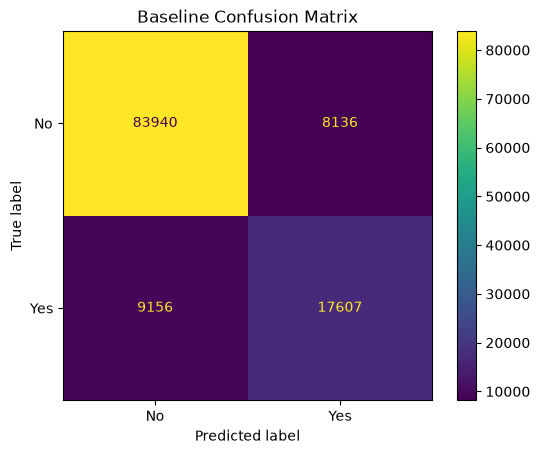

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_pred,
    display_labels=["No", "Yes"]
)

plt.title("Baseline Confusion Matrix")
plt.show()